# DailyDialog · Informe de generación de respuestas

Este informe evalúa un Transformer entrenado para responder a intervenciones de conversaciones cotidianas en inglés. Se comparan dos configuraciones de atención y se analiza tanto la coincidencia con las respuestas de referencia como la pertinencia de lo que redacta el modelo.

**Uso en Colab.** Puedes leer las tablas y los gráficos ya guardados. Para repetir el experimento, selecciona *Entorno de ejecución → Ejecutar todas* y, si se solicita, sube el archivo `dataset 3ra evaluacion.zip`.

### Bibliotecas y mensajes de inicio

**Qué ocurre al ejecutar la primera celda.** Python carga las bibliotecas. TensorFlow y Keras construyen y entrenan las redes, NumPy organiza los datos en arreglos numéricos, pandas presenta las tablas y Matplotlib dibuja las curvas. La semilla numérica `42` ayuda a repetir el sorteo de muestras y la inicialización de los modelos. El equipo y las versiones instaladas pueden producir pequeñas diferencias.

**Cómo leer el aviso largo de Protobuf.** Protobuf es el formato que TensorFlow usa para representar datos estructurados. En la ejecución guardada, parte del código de TensorFlow se había generado con Protobuf **5.28.3**, y Python tenía instalada la versión **6.31.1** para ejecutarlo. La línea `UserWarning` avisa de esa diferencia y de una posible incompatibilidad en una versión futura. La ruta que empieza con `C:\Users\…` identifica el archivo de la biblioteca que emitió el aviso. Nombres como `tensor.proto` y `attr_value.proto` indican distintas definiciones que pasaron por la misma comprobación.

El entrenamiento continuó y dejó resultados guardados. En esta edición se conserva un ejemplo del aviso cuando apareció en la salida original. Al reejecutar en Colab, los avisos dependen de las versiones de ese entorno. Si una celda se detiene, la última línea del bloque `Traceback` identifica el error que sí interrumpió esa ejecución.

In [1]:
import ast
import io
import re
import zipfile
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display, Markdown

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
libro = Path("Don Quijote de la Mancha.txt")
archivo_zip = Path("dataset 3ra evaluacion.zip")
if not all(p.is_file() for p in [archivo_zip]):
    from google.colab import files
    print("Selecciona dataset 3ra evaluacion.zip.")
    files.upload()
for p in [archivo_zip]:
    if not p.is_file():
        raise FileNotFoundError(f"Falta {p.name}. Súbelo al directorio del cuaderno.")
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## Entregable 3.2 · Respuestas conversacionales con DailyDialog
### 1. De conversaciones a pares de entrenamiento
El ZIP del curso contiene tres archivos CSV, cada uno con una conversación por fila. La columna *dialog* guarda varias intervenciones entre comillas. Las columnas *act* y *emotion* describen cada intervención. Para esta tarea generativa la entrada es un turno y la respuesta esperada es el turno inmediatamente posterior.

Respetamos las particiones oficiales. Comprobamos que el número de turnos extraídos coincide con el número de actos, descartamos pares idénticos repetidos y evitamos usar un par de entrenamiento como ejemplo de evaluación. Seleccionamos una muestra reproducible de cada partición. Así podemos comparar varios entrenamientos con el mismo presupuesto.

**Qué representa una fila.** Un *turno* es lo que dice una persona antes de que otra responda. Una conversación de tres turnos A, B y C produce dos ejemplos, A → B y B → C. La *referencia* es lo que efectivamente respondió la otra persona. El archivo también contiene el tipo de intervención (`act`) y la emoción anotada (`emotion`). La tarea utiliza el texto como objetivo y aprovecha la cantidad de actos para comprobar que se leyeron correctamente todos los turnos.

**Cómo leer la tabla de datos.** *Diálogos* cuenta conversaciones. *Pares originales* cuenta intervenciones consecutivas. *Pares únicos disponibles* descuenta repeticiones y pares ya vistos en una partición anterior. *Pares usados* cuenta los que realmente entraron al experimento. De los 11 118 diálogos de entrenamiento se obtuvieron 76 052 pares antes de quitar duplicados. Se entrenó con una muestra de 12 000 y se reservaron muestras de 384 para validación y 384 para prueba. Las frases en inglés que aparecen en esta primera tabla provienen del archivo.

In [2]:
patron_turno = re.compile(r"""'(?:[^'\\]|\\.)*'|"(?:[^"\\]|\\.)*" """.strip())

def normalizar(frase):
    return " ".join(re.findall(r"\w+|[^\w\s]", frase.lower().replace("’","'")))

def leer_pares(df):
    pares = []
    for fila in df.itertuples(index=False):
        turnos = [normalizar(ast.literal_eval(v)) for v in patron_turno.findall(fila.dialog)]
        if len(turnos) != len(fila.act.strip("[]").split()):
            raise ValueError("No coincide la cantidad de turnos con la columna act.")
        pares.extend((a,b) for a,b in zip(turnos, turnos[1:]) if a and b)
    return pares

partes_d, vistos, resumen = {}, set(), []
with zipfile.ZipFile(archivo_zip) as z:
    for nombre, limite in [("train",12000), ("validation",384), ("test",384)]:
        with z.open(nombre+".csv") as f:
            df = pd.read_csv(f)
        pares = leer_pares(df)
        disponibles = list(dict.fromkeys(p for p in pares if p not in vistos))
        vistos.update(disponibles)
        indices = np.random.default_rng(SEMILLA).choice(len(disponibles), min(limite,len(disponibles)), replace=False)
        partes_d[nombre] = [disponibles[i] for i in indices]
        resumen.append([nombre,len(df),len(pares),len(disponibles),len(indices)])
display(pd.DataFrame(resumen,columns=["partición","diálogos","pares originales","pares únicos disponibles","pares usados"]))
display(pd.DataFrame(partes_d["train"][:3],columns=["intervención","siguiente turno"]))

,partición,diálogos,pares originales,pares únicos disponibles,pares usados
0,train,11118,76052,67169,12000
1,validation,1000,7069,5678,384
2,test,1000,6740,5094,384


,intervención,siguiente turno
0,"well , what do you think about our very own ho...",i don ' t want to be cooped up in my own hotel...
1,how can it be cliche ? it ' s a fable ! it ' s...,"you have always been so soft , dave !"
2,"ok , i promise we ' ll get there in twenty min...",thanks .


### 2. Representación del diálogo
El vocabulario se obtiene solo de los pares de entrenamiento elegidos. Reservamos identificadores para relleno, palabras desconocidas, comienzo y fin de respuesta. Conservamos hasta 23 palabras o signos por turno. En entrenamiento, el decoder recibe la respuesta desplazada una posición. En prueba solo recibe la intervención y el marcador de inicio. Al calcular ROUGE usamos la respuesta original completa como referencia, incluidas las palabras fuera del vocabulario.

**Ejemplo de preparación.** Si la respuesta real fuera `yes please`, el decoder recibiría `INICIO yes please` durante el entrenamiento. Sus objetivos sucesivos serían `yes`, `please` y `FIN`. De esa manera aprende qué sigue en cada posición. Al responder una pregunta nueva, empieza solo con `INICIO` y continúa usando sus propias palabras.

| Símbolo o variable | Para qué sirve |
|---|---|
| `PAD` | Completa las filas cortas para formar lotes rectangulares. Se excluye al calcular la pérdida. |
| `UNK` | Representa un término fuera del vocabulario aprendido. |
| `INICIO` y `FIN` | Marcan dónde comienza la generación y cuándo terminarla. |
| `LARGO = 24` | Se usan hasta 23 palabras o signos más un marcador por secuencia. |
| `V = 2000` | Hay 1 996 términos frecuentes y cuatro símbolos especiales. La puntuación también puede ocupar una posición. |
| `(12000, 24)` | La primera cifra cuenta ejemplos de entrenamiento y la segunda, posiciones por ejemplo. |

In [3]:
LARGO = 24
PAD, UNK, INICIO, FIN = range(4)
frecuencias = Counter(p for par in partes_d["train"] for s in par for p in s.split())
palabras = ["<pad>", "<unk>", "<inicio>", "<fin>"] + [p for p,_ in frecuencias.most_common(1996)]
a_id = {p:i for i,p in enumerate(palabras)}
V = len(palabras)

def preparar_pares(pares):
    x, prefijo, objetivo = [], [], []
    for a,b in pares:
        origen, respuesta = [[a_id.get(p,UNK) for p in s.split()[:LARGO-1]] for s in (a,b)]
        x.append(origen+[FIN])
        prefijo.append([INICIO]+respuesta)
        objetivo.append(respuesta+[FIN])
    return [keras.utils.pad_sequences(v,maxlen=LARGO,padding="post",value=PAD) for v in (x,prefijo,objetivo)]

arrays_d = {k:preparar_pares(v) for k,v in partes_d.items()}
print(f"Vocabulario: {V} símbolos. Entrada de entrenamiento: {arrays_d['train'][0].shape}.")

Vocabulario: 2000 símbolos. Entrada de entrenamiento: (12000, 24).


### 3. Encoder y decoder con atención de varias cabezas
El encoder combina vectores de palabra y de posición. Su autoatención relaciona palabras del turno de entrada. Cada cabeza puede ponderar relaciones distintas. Las conexiones residuales y la normalización acompañan tanto a la atención como a la red densa que sigue.

El decoder tiene autoatención causal para ocultar las palabras futuras y atención cruzada para consultar el encoder. La capa final produce una puntuación por palabra. Las máscaras excluyen posiciones de relleno y la pérdida ignora el relleno de las etiquetas.

**Sigue una pregunta a través del modelo.** El *embedding* convierte cada identificador de palabra en un vector de 48 números. Otro vector aporta su posición. El **encoder** relaciona las palabras de la pregunta mediante *autoatención* y produce una representación por posición. El **decoder** combina lo que lleva escrito con esas representaciones mediante *atención cruzada*. Su capa final puntúa las posibles palabras siguientes.

**Qué significan las piezas del código.** Una *cabeza* calcula una manera de ponderar relaciones entre posiciones. En el experimento se reparte el mismo ancho de 48 entre dos o cuatro cabezas. La *máscara causal* impide que el decoder lea una palabra futura de la respuesta durante el entrenamiento. La *conexión residual* suma la entrada a la transformación para conservar información previa. La *normalización* reajusta la escala de los valores y *dropout* desactiva aleatoriamente parte de ellos durante el entrenamiento. La red densa intermedia transforma cada posición de 48 a 96 valores y luego vuelve a 48.

In [4]:
def bloque_denso(x, dim, ff):
    h = layers.Dense(ff,activation="relu")(x)
    h = layers.Dense(dim)(h)
    return layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(.1)(h))

def crear_transformer(cabezas):
    dim, ff = 48, 96
    x = keras.Input((LARGO,),dtype="int32",name="turno")
    y = keras.Input((LARGO,),dtype="int32",name="prefijo")
    # La capa de posición debe ser parte del modelo y aprender con él.
    pos = layers.Embedding(LARGO,dim,name="posiciones")
    def representar(ids):
        posiciones = keras.ops.cumsum(keras.ops.ones_like(ids), axis=1) - 1
        return layers.Embedding(V,dim)(ids) + pos(posiciones)
    a, b = representar(x), representar(y)
    mascara_x = keras.ops.expand_dims(keras.ops.not_equal(x,PAD),axis=1)
    mascara_y = keras.ops.expand_dims(keras.ops.not_equal(y,PAD),axis=1)
    def atencion(q,kv,mascara,causal=False):
        h = layers.MultiHeadAttention(num_heads=cabezas,key_dim=dim//cabezas)(
            query=q,value=kv,key=kv,attention_mask=mascara,use_causal_mask=causal)
        return layers.LayerNormalization(epsilon=1e-6)(q + layers.Dropout(.1)(h))
    memoria = bloque_denso(atencion(a,a,mascara_x),dim,ff)
    b = atencion(b,b,mascara_y,True)
    b = bloque_denso(atencion(b,memoria,mascara_x),dim,ff)
    logits = layers.Dense(V)(b)
    modelo = keras.Model([x,y],logits)
    modelo.compile(keras.optimizers.Adam(.001),
                   loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True,ignore_class=PAD))
    return modelo

### 4. Generación y métrica
En cada posición tomamos la palabra con mayor puntuación hasta leer el fin de respuesta o alcanzar el límite. Usamos **ROUGE-L F1**, que mide cuánto texto comparten la salida y la referencia respetando el orden. Calculamos la subsecuencia común más larga por par y promediamos. Excluimos los signos de puntuación de esta métrica para que una respuesta no reciba crédito solo por acertar el punto final.

Una conversación admite varias respuestas razonables y el archivo ofrece una sola referencia por turno. Por eso también leemos salidas reales y comprobamos si el modelo repite respuestas genéricas.

**Qué es ROUGE-L con un ejemplo pequeño.** Si la referencia fuera `yes of course` y el modelo escribiera `yes certainly`, la subsecuencia compartida sería `yes`. De dos palabras generadas coincide una, y de tres palabras esperadas se recupera una. El F1 correspondiente es 0,40. La L de ROUGE-L se refiere a la subsecuencia común más larga. Las palabras pueden estar separadas, pero deben conservar su orden.

En este cuaderno se calcula el puntaje por respuesta y se toma el promedio. Un valor 1 corresponde a coincidencia completa de los términos evaluados y 0 a ninguna palabra compartida. Una paráfrasis razonable puede obtener poco puntaje. En sentido inverso, repetir palabras frecuentes puede dar puntos aunque la respuesta sea poco pertinente. La tabla cualitativa del final permite contrastarlo.

In [5]:
def generar_respuestas(modelo, x):
    @tf.function(reduce_retracing=True)
    def decodificar(entrada):
        n = tf.shape(entrada)[0]
        prefijo = tf.concat([tf.fill([n,1],INICIO),tf.zeros([n,LARGO-1],tf.int32)],axis=1)
        salida = tf.TensorArray(tf.int32,size=LARGO)
        terminada = tf.zeros([n],tf.bool)
        for t in tf.range(LARGO):
            logits = modelo([entrada,prefijo],training=False)[:,t,:]
            # Solo FIN y las palabras del vocabulario pueden salir.
            token = tf.argmax(logits[:,FIN:],axis=1,output_type=tf.int32) + FIN
            token = tf.where(terminada,FIN,token)
            terminada = terminada | (token == FIN)
            salida = salida.write(t,token)
            prefijo = prefijo + token[:,None]*tf.one_hot(t+1,LARGO,dtype=tf.int32)[None,:]
        return tf.transpose(salida.stack())
    ids = np.concatenate([decodificar(tf.constant(x[i:i+64])).numpy() for i in range(0,len(x),64)])
    return [" ".join(palabras[j] for j in fila if j != FIN) for fila in ids]

def rouge_l(referencia, salida):
    r,p = [[w for w in s.split() if any(c.isalnum() for c in w)] for s in (referencia,salida)]
    anterior = [0]*(len(p)+1)
    for a in r:
        actual = [0]
        for j,b in enumerate(p,1):
            actual.append(anterior[j-1]+1 if a==b else max(anterior[j],actual[-1]))
        anterior = actual
    return 2*anterior[-1]/max(1,len(r)+len(p))

def evaluar_dialogo(modelo,particion):
    propuestas = generar_respuestas(modelo, arrays_d[particion][0])
    df = pd.DataFrame(partes_d[particion],columns=["turno","referencia"])
    df["generada"] = propuestas
    df["ROUGE-L"] = [rouge_l(r,p) for r,p in zip(df.referencia,propuestas)]
    return df

### 5. Comparación de configuraciones
Entrenamos el mismo encoder-decoder con dos y cuatro cabezas. Mantenemos constantes el ancho de representación, las capas, los datos, la tasa, el lote y las cuatro épocas. Seleccionamos según ROUGE-L medio de validación y luego medimos en la partición de prueba. La pérdida de validación se calcula con el prefijo correcto. ROUGE-L se calcula con texto generado sin conocer la respuesta.

**Qué cambia y qué se mantiene.** Un *hiperparámetro* es una decisión que fijamos antes de entrenar. Aquí variamos las cabezas de atención. Ambos modelos recorren cuatro veces los mismos 12 000 pares, en lotes de 64 y con tasa de aprendizaje 0,001. La tasa determina el tamaño de los pasos de ajuste del optimizador.

**Cómo leer la comparación.** En la columna *pérdida de validación* se prefiere un valor bajo. En *ROUGE-L de validación* se prefiere un valor alto. La primera mide predicciones cuando el modelo dispone del prefijo correcto y la segunda mide lo que consigue redactar por sí mismo. *Respuestas distintas* cuenta cuántos textos diferentes produjo para 384 entradas. El gráfico muestra la evolución de la pérdida, con una línea por cantidad de cabezas.

,cabezas,pérdida validación,ROUGE-L validación,respuestas distintas
0,2,3.6276,0.0685,57
1,4,3.6362,0.0690,75


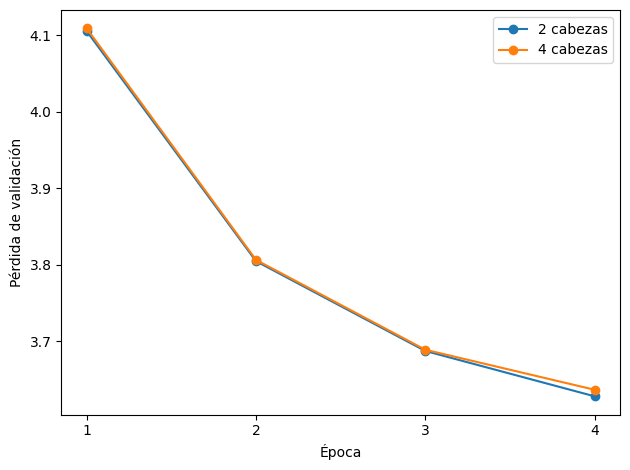

In [6]:
resumen_t, curvas_t = [], {}
mejor_rouge = -1
x_d, y_d, z_d = arrays_d["train"]
x_v, y_v, z_v = arrays_d["validation"]
for cabezas in (2,4):
    keras.utils.set_random_seed(SEMILLA)
    transformer = crear_transformer(cabezas)
    h = transformer.fit([x_d,y_d],z_d,validation_data=([x_v,y_v],z_v),
                        batch_size=64,epochs=4,verbose=0)
    curvas_t[cabezas] = h.history
    ev = evaluar_dialogo(transformer,"validation")
    puntuacion = ev["ROUGE-L"].mean()
    resumen_t.append([cabezas,h.history["val_loss"][-1],puntuacion,ev.generada.nunique()])
    if puntuacion > mejor_rouge:
        mejor_rouge, mejores_cabezas, pesos_t = puntuacion, cabezas, transformer.get_weights()
display(pd.DataFrame(resumen_t,columns=["cabezas","pérdida validación","ROUGE-L validación","respuestas distintas"]).round(4))
for cabezas,h in curvas_t.items():
    plt.plot(range(1,5),h["val_loss"],marker="o",label=f"{cabezas} cabezas")
plt.xlabel("Época"); plt.ylabel("Pérdida de validación"); plt.xticks(range(1,5))
plt.legend(); plt.tight_layout(); plt.show()

### 6. ¿Qué responde el modelo elegido?
Mostramos entradas, referencias y respuestas para tres ejemplos fijos y el ejemplo con mayor coincidencia en la muestra. Este último ilustra el mejor caso observado. También medimos la frecuencia de la respuesta más repetida. Una salida frecuente puede obtener coincidencias léxicas y aun así aportar poca información para una pregunta concreta.

**Cómo leer una fila de prueba.** Lee primero *turno*, la intervención que recibió el modelo. Luego compara *referencia*, la respuesta del diálogo original, con *generada*, la predicción del Transformer. Pregúntate si responde realmente a la persona, si termina la frase y si repite expresiones. Después mira ROUGE-L. El valor de una fila describe ese ejemplo, mientras que el promedio del informe resume los 384 pares. Las comillas separadas en formas como `i ' m` se deben a que el preprocesamiento trata el apóstrofo como un signo separado.

In [7]:
final_t = crear_transformer(mejores_cabezas)
final_t.set_weights(pesos_t)
prueba_t = evaluar_dialogo(final_t,"test")
frecuente = prueba_t.generada.value_counts()
indices = list(dict.fromkeys([0,1,2,prueba_t["ROUGE-L"].idxmax()]))
with pd.option_context("display.max_colwidth",None):
    display(prueba_t.loc[indices].round(3))
display(Markdown(f"**Conclusión de diálogo.** Se eligieron **{mejores_cabezas} cabezas** "
                 f"por su ROUGE-L en validación ({mejor_rouge:.3f}). En {len(prueba_t)} "
                 f"pares de prueba, el ROUGE-L medio fue **{prueba_t['ROUGE-L'].mean():.3f}** "
                 f"en escala de 0 a 1. Aparecieron {len(frecuente)} respuestas distintas. "
                 f"La más repetida fue «{frecuente.index[0]}», en {frecuente.iloc[0]} casos."))

,turno,referencia,generada,ROUGE-L
0,sure . do you want it to be registered ?,"yes , i think so . there are some pictures in it . it would be a great pity if they were lost .","i ' m sorry , but i ' m not sure .",0.071
1,yes . it ' s nice to meet you too . are you a new student too ?,no . i ' m a sophomore . i take it you are a new student ?,i ' m sorry . i ' m sorry . i ' m sorry . i ' m not sure you can ',0.286
2,"not much . i had to pay an unexpected bill , so i needed the money back .","well , talk to him about it next time you see him . he probably feels as bad about it as you do . close friends sometimes have disagreements . it ' s nothing unusual . neither of you said anything really nasty , did you ?","i ' m sorry , but i ' m sorry .",0.000
383,"when was america discovered , tony ?",i ' m not certain . do you know ?,i ' m not a good .,0.500


**Conclusión de diálogo.** Se eligieron **4 cabezas** por su ROUGE-L en validación (0.069). En 384 pares de prueba, el ROUGE-L medio fue **0.069** en escala de 0 a 1. Aparecieron 84 respuestas distintas. La más repetida fue «i ' m not sure .», en 90 casos.

### Interpretación de la ejecución guardada

**Dos frente a cuatro cabezas.** En validación, el ROUGE-L pasó de 0,0685 a 0,0690. Cuatro cabezas generaron 75 respuestas distintas frente a 57 con dos cabezas. La diferencia de ROUGE-L es pequeña y depende de esta muestra y esta semilla. La pérdida favoreció levemente a dos cabezas. Esto es posible porque la pérdida mide predicciones con el prefijo correcto, mientras que ROUGE-L mide la respuesta que el modelo produce por sí mismo.

**Qué significa el resultado de prueba.** Ante la pregunta de si se quiere registrar un envío, el modelo responde «I'm sorry, but I'm not sure». La frase es plausible en una conversación, pero omite la decisión y el motivo que sí aparecen en la referencia. Cuando le preguntan si es un estudiante nuevo, repite una disculpa en vez de responder. Incluso el ejemplo con ROUGE-L de 0,500 termina en «I'm not a good», una frase incompleta. Compartir palabras con la referencia puede sumar puntos aunque la respuesta aporte poca información.

**Límite observado.** La respuesta «I'm not sure» apareció en 90 de 384 casos, casi uno de cada cuatro. Con solo el turno anterior y 12 000 pares de entrenamiento, el sistema aprendió expresiones frecuentes y mostró poca variedad. Un siguiente ensayo podría incorporar más contexto y comprobar si baja esa frecuencia sin perder pertinencia.


## Discusión y defensa
**Qué aprende cada modelo.** La recurrente reduce 30 caracteres a un estado que resume el contexto. Es adecuada para observar regularidades de ortografía y terminaciones. Al generar muchos caracteres puede repetir secuencias y perder el hilo. El Transformer conserva un vector por posición del turno inicial y consulta esos vectores al redactar cada palabra. La atención facilita relacionar palabras distantes y permite procesar posiciones en paralelo durante el entrenamiento. Al generar, ambos modelos necesitan sus propias salidas anteriores.

**Cómo interpretar la comparación.** En el Quijote se evalúa si se acierta el carácter exacto. En DailyDialog se mide coincidencia de palabras en una respuesta abierta. Para decidir qué arquitectura rinde más en una misma tarea habría que entrenarlas con los mismos datos, objetivo y métrica. Aquí la elección se justifica dentro de cada experimento.

**Siguiente experimento.** Para la novela, aumentaría las ventanas de entrenamiento y mediría si mejora el F1 de los caracteres menos frecuentes. Para el diálogo, ampliaría la muestra y probaría dos turnos de contexto. Compararía ROUGE-L, diversidad y pertinencia de las respuestas sobre las mismas preguntas de validación.

